# California Housing Dataset
## Problem framing and data-generating context

### Problem statement
We will predict the median house value of a California census block group from 1990 census-derived socioeconomic, housing, population, and geographic measurements. `MedHouseVal` is measured in hundreds of thousands of dollars and capped at 5.0, so this is prediction of the recorded historical target, not uncensored current-market valuation. The cap makes high-value errors especially important because values above $500,000 are indistinguishable.

### Unit of observation and target
- **One row:** one California census block group, typically containing about 600–3,000 people; it is not an individual household or property.
- **Target:** `MedHouseVal`, the block-group median house value in $100,000 units, top-coded at 5.0.
- **Context:** the data comes from the 1990 U.S. Census and is not representative of present-day prices.

### Data dictionary

| Column | Meaning | Role and caveat |
|---|---|---|
| `MedInc` | Median income in the block group | Aggregate socioeconomic predictor, not household income |
| `HouseAge` | Median house age | Predictor; does not directly measure condition |
| `AveRooms` | Average rooms per household | Ratio; extremes can reflect small denominators or vacation areas |
| `AveBedrms` | Average bedrooms per household | Ratio with the same small-denominator risk |
| `Population` | Block-group population | Geographic-unit count, not property or household count |
| `AveOccup` | Average household members | Aggregate occupancy ratio |
| `Latitude` | Block-group latitude | Geographic predictor and regional proxy |
| `Longitude` | Block-group longitude | Geographic predictor and regional proxy |
| `MedHouseVal` | Median house value | Target in $100,000 units, capped at 5.0 |

### Facts, assumptions, and risks

**Facts:** 20,640 rows; eight numeric predictors; no documented missing attributes; one row per census block group; data derived from the 1990 U.S. Census; `MedHouseVal` includes the known 5.0 cap.

**Assumptions:** block-group aggregates are useful predictors of the block-group median; geographic variables capture meaningful location effects; the published capped target remains the main target, while uncapped-only analysis is sensitivity analysis; relationships are historical and should not be deployed as current-market estimates.

**Risks and uncertainties:** target censoring hides differences above $500,000; nearby block groups may violate independence and make random splits optimistic; temporal shift limits present-day validity; aggregate measurements do not support individual-household conclusions; dataset construction may not represent all California markets equally.

### Testable hypotheses
1. Higher `MedInc` is associated with higher `MedHouseVal`, with diminishing returns.
2. `Latitude` and `Longitude` explain substantial geographic structure beyond non-geographic variables.
3. `AveRooms` is positively associated with value, but extreme values partly reflect small denominators.
4. `AveOccup` has a nonlinear relationship with value, with unusually high occupancy associated with lower values.
5. `HouseAge` has a weaker and potentially non-monotonic relationship with value than `MedInc`.
6. Capped rows behave differently from uncapped rows and should be compared during evaluation.

### Solution notes and validation
This framing changes the notebook from generic column exploration to a historical, block-group-level supervised-learning problem. `Latitude` and `Longitude` are geographic predictors and possible sources of spatial leakage; average room fields are ratios whose extremes need denominator-aware interpretation. Remaining questions are how geographic splits change estimated performance, how to report capped-target errors, and whether these hypotheses persist after a leakage-safe split. A reader can now identify the prediction target, row unit, historical scope, column roles, limitations, and next EDA hypotheses.

# California Housing: Data Exploration

Goal: understand the features, target variable, data quality, distributions, relationships, and possible problems before building regression models.

Questions:
- What does each feature represent?
- Which features are related to house value?
- Are there missing values or outliers?
- Which features may require scaling or transformation?
- Does a linear relationship seem reasonable?

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

In [10]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [11]:
housing.DESCR

'.. _california_housing_dataset:\n\nCalifornia Housing dataset\n--------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 20640\n\n:Number of Attributes: 8 numeric, predictive attributes and the target\n\n:Attribute Information:\n    - MedInc        median income in block group\n    - HouseAge      median house age in block group\n    - AveRooms      average number of rooms per household\n    - AveBedrms     average number of bedrooms per household\n    - Population    block group population\n    - AveOccup      average number of household members\n    - Latitude      block group latitude\n    - Longitude     block group longitude\n\n:Missing Attribute Values: None\n\nThis dataset was obtained from the StatLib:\nhttps://lib.stat.cmu.edu/datasets/houses.zip\n\nThe target variable is the median house value for California districts,\nexpressed in hundreds of thousands of dollars ($100,000).\n\nThis dataset was derived from the 1990 U.S. census, using one row per

In [12]:
df.shape

(20640, 9)

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Datasetcontains :
<li>20k+ records of houses.</li>
<li>8 input columns/features</li>
<li>Target range is (500k$ - 200k$) = 300k$</li>
<li>features with very different scale: Population</li>
<li>features with Suspicious minimum or maximum values: AveRooms,AveBedrms,AveOccup</li>


In [14]:
df.isna().sum() # no missing values

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [15]:
df.duplicated().sum() # no duplicate rows

np.int64(0)

In [16]:
df.nunique().sort_values()

HouseAge          52
Longitude        844
Latitude         862
MedHouseVal     3842
Population      3888
MedInc         12928
AveBedrms      14233
AveOccup       18841
AveRooms       19392
dtype: int64

In [17]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [18]:
df.corr() #columns 'AveRooms' and 'AveBedrms' are highly correlated. 
# latitude and longitude are also higly correlated.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


In [19]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


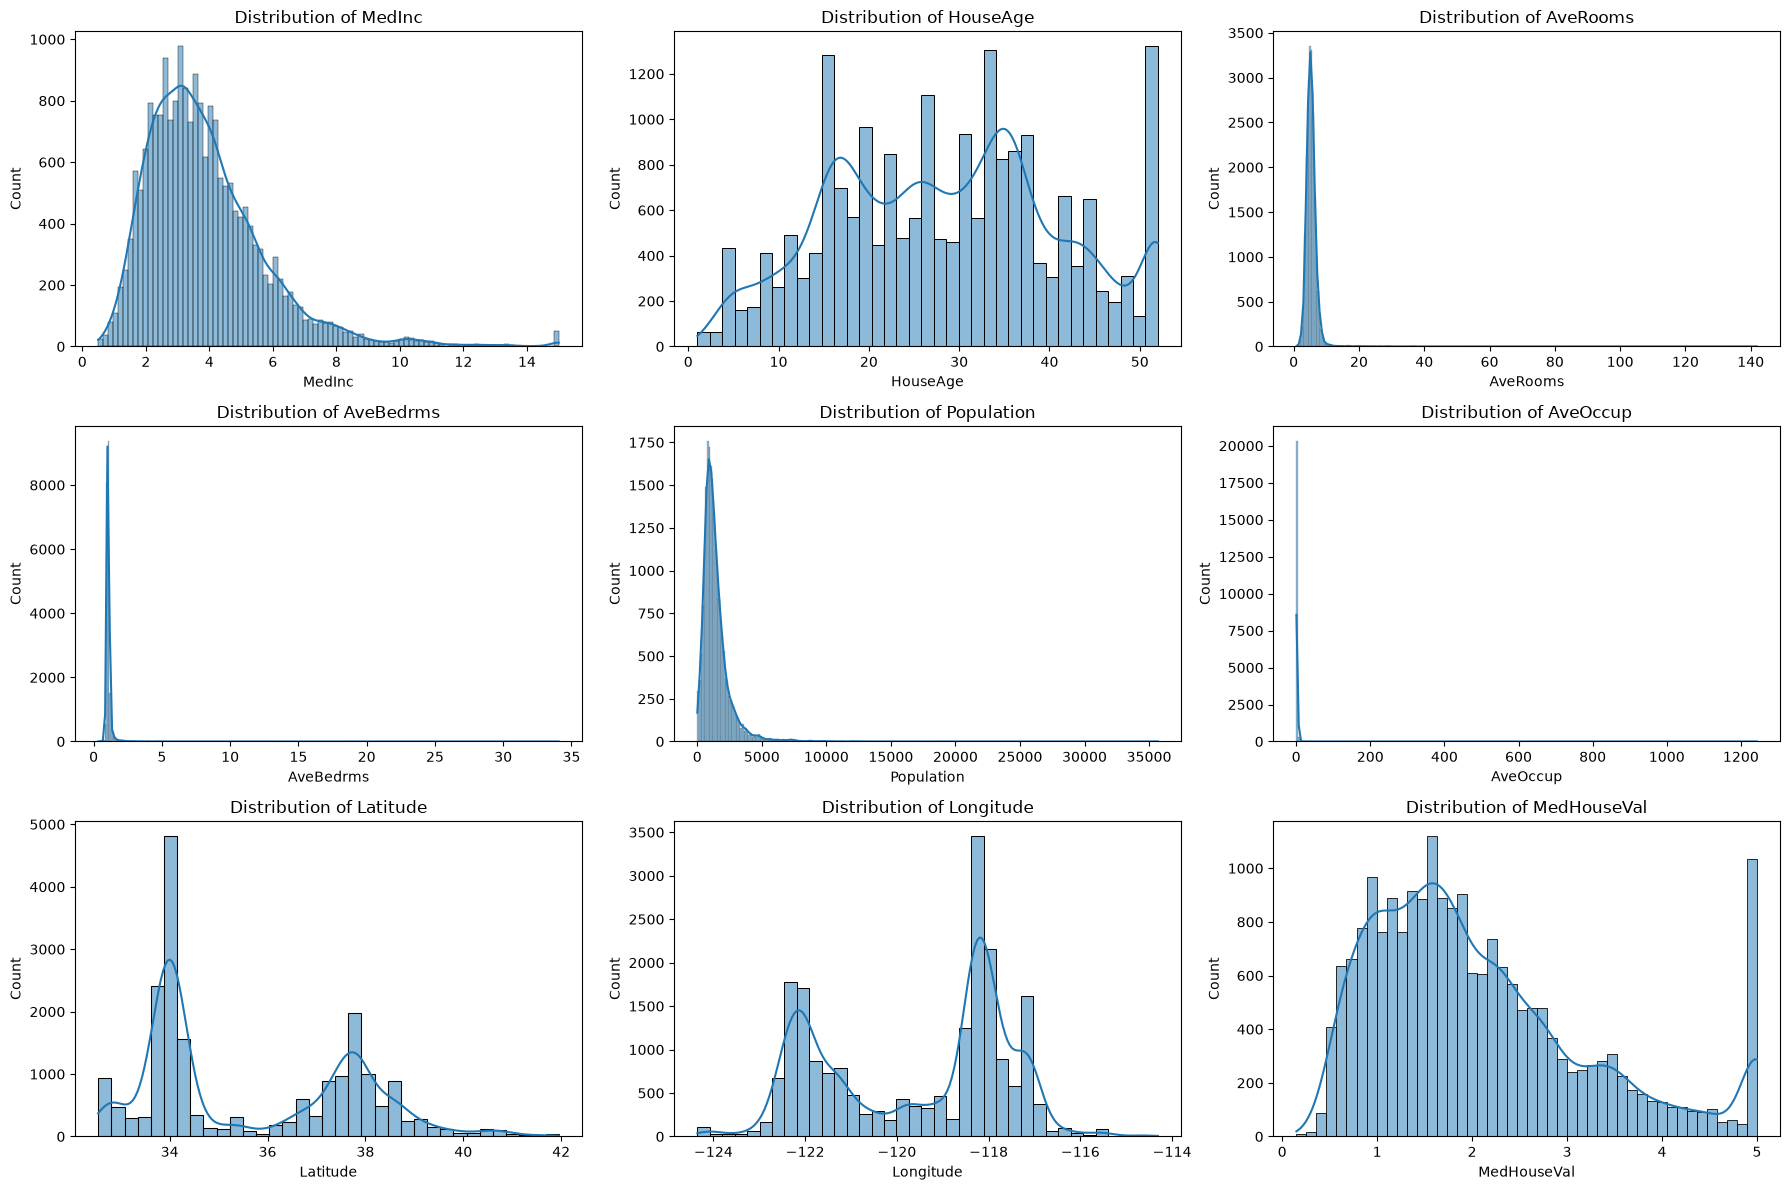

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.ravel()
for ax, column in zip(axes, df.columns):
    sns.histplot(df[column], kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

# Analyzing the target variable

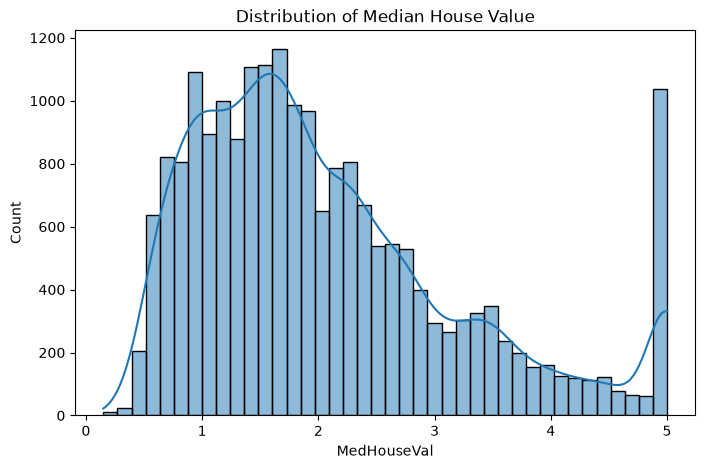

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.show()

In [22]:
df['MedHouseVal'].describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

# Percentage of Values at the Target's ceiling.

In [74]:
(df['MedHouseVal'] >= 5.0).mean() * 100 # checking the percentage of values capped at 5 in target column

np.float64(4.8062015503875966)

# Checking model performance before Preprocessing.

In [25]:
X = df.drop(columns=['MedHouseVal'])
y = df.iloc[:,-1]

In [26]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 2
X_train,X_test,y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# leakage-safe evaluation design

### Primary split choice
The primary evaluation uses a reproducible random 80/20 split with `RANDOM_STATE = 2`. The test set represents other California census block groups from the same 1990 snapshot, not future housing markets. This keeps the first modeling workflow simple and provides a stable baseline for comparing models.

The random split may be optimistic because nearby block groups can occur in both training and test sets and share spatial structure. A spatial holdout or spatial cross-validation would be a stronger alternative for measuring performance on geographically distinct areas, but it can introduce regional distribution shift and reduce the effective sample size. A later temporal evaluation using a newer census would be needed to assess future-year deployment; this dataset does not provide that test population.

### Test-set boundary and validation
The test set is created once and remains untouched during feature selection, preprocessing decisions, model comparison, and hyperparameter tuning. Validation must use only the training portion, through a validation split or cross-validation, and the final test score is reported only after those decisions are complete. The current notebook's baseline model uses the held-out test set only for its final evaluation.

### Leakage controls
- Split `X` and `y` before model fitting; `MedHouseVal` must never appear in the feature matrix or in target-derived features.
- Fit scaling, imputation, transformations, feature selection, and outlier thresholds on training data only, then transform validation and test data.
- Do not use test performance to select features, remove observations, choose transformations, or tune hyperparameters.
- Do not construct neighborhood features using target values from held-out rows.
- Treat the 5.0 target cap as a property of the published target, not as a feature; keep capped-row handling consistent across splits.

### Limitations
This random holdout estimates generalization to another random 1990 block group and does not establish temporal stability or performance in geographically unseen regions. The spatial alternative should be revisited if the deployment goal changes from same-population estimation to prediction for new areas.

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
lr = LinearRegression()

In [28]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6013853272055154

In [29]:
df_uncapped = df[df['MedHouseVal'] < 5.0].copy()
df_uncapped.shape


(19648, 9)

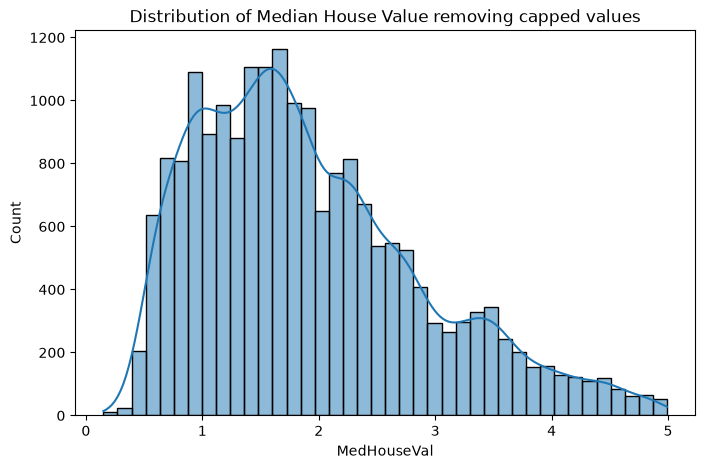

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_uncapped, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value removing capped values")
plt.show()

In [31]:
feature_columns = df.columns.drop("MedHouseVal")

train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.2,
    random_state=2
)

# Model 1: trained on all original training rows
model_all = LinearRegression()
model_all.fit(
    df.loc[train_indices, feature_columns],
    df.loc[train_indices, "MedHouseVal"]
)

# Model 2: trained only on uncapped rows from the same training set
uncapped_train_indices = train_indices[
    df.loc[train_indices, "MedHouseVal"] < 5.0
]

model_uncapped = LinearRegression()
model_uncapped.fit(
    df.loc[uncapped_train_indices, feature_columns],
    df.loc[uncapped_train_indices, "MedHouseVal"]
)

# Both models evaluated on the exact same original test set
X_test_common = df.loc[test_indices, feature_columns]
y_test_common = df.loc[test_indices, "MedHouseVal"]

r2_all = r2_score(
    y_test_common,
    model_all.predict(X_test_common)
)

r2_uncapped = r2_score(
    y_test_common,
    model_uncapped.predict(X_test_common)
)

print("R², model trained on all rows:", r2_all)
print("R², model trained without capped training rows:", r2_uncapped)

R², model trained on all rows: 0.6013853272055154
R², model trained without capped training rows: 0.5959199044689703


In [32]:
uncapped_test_indices = test_indices[
    df.loc[test_indices, "MedHouseVal"] < 5.0
]

X_uncapped_test = df.loc[uncapped_test_indices, feature_columns]
y_uncapped_test = df.loc[uncapped_test_indices, "MedHouseVal"]

print(
    "All-row model on uncapped test rows:",
    r2_score(y_uncapped_test, model_all.predict(X_uncapped_test))
)

print(
    "Uncapped model on uncapped test rows:",
    r2_score(y_uncapped_test, model_uncapped.predict(X_uncapped_test))
)

All-row model on uncapped test rows: 0.5776375685145484
Uncapped model on uncapped test rows: 0.5827825015218753


## Conclusion: keep the original target for the main model

The value `5.0` in `MedHouseVal` is a capped target value, not a separate column and not necessarily an ordinary outlier. In this dataset, it represents a median house value of at least 500,000 dollars, but values above that level are recorded as `5.0`.

For the main model, keep the target variable and all observations intact. This preserves the original prediction problem and allows the model to learn from the complete dataset.

The capped-row experiment was useful as a sensitivity analysis:

- On the same original test set, the model trained on all rows achieved an R² of `0.6014`, compared with `0.5959` for the model trained without capped training rows.
- On only the uncapped test rows, the all-row model achieved `0.5776`, compared with `0.5828` for the uncapped-training model.

Removing capped training rows helped slightly for uncapped houses but reduced performance on the complete test set. Therefore, there is no strong reason to remove those rows from the primary analysis. Keep this experiment as a comparison, and use cross-validation for a more reliable estimate before choosing a final model.

If the goal is specifically to predict values only below the cap, the uncapped experiment can be treated as a separate modeling problem. Otherwise, keep `MedHouseVal` intact. 

## Bivariate Analysis:
 Analyzing the relationship between each feature and the target.



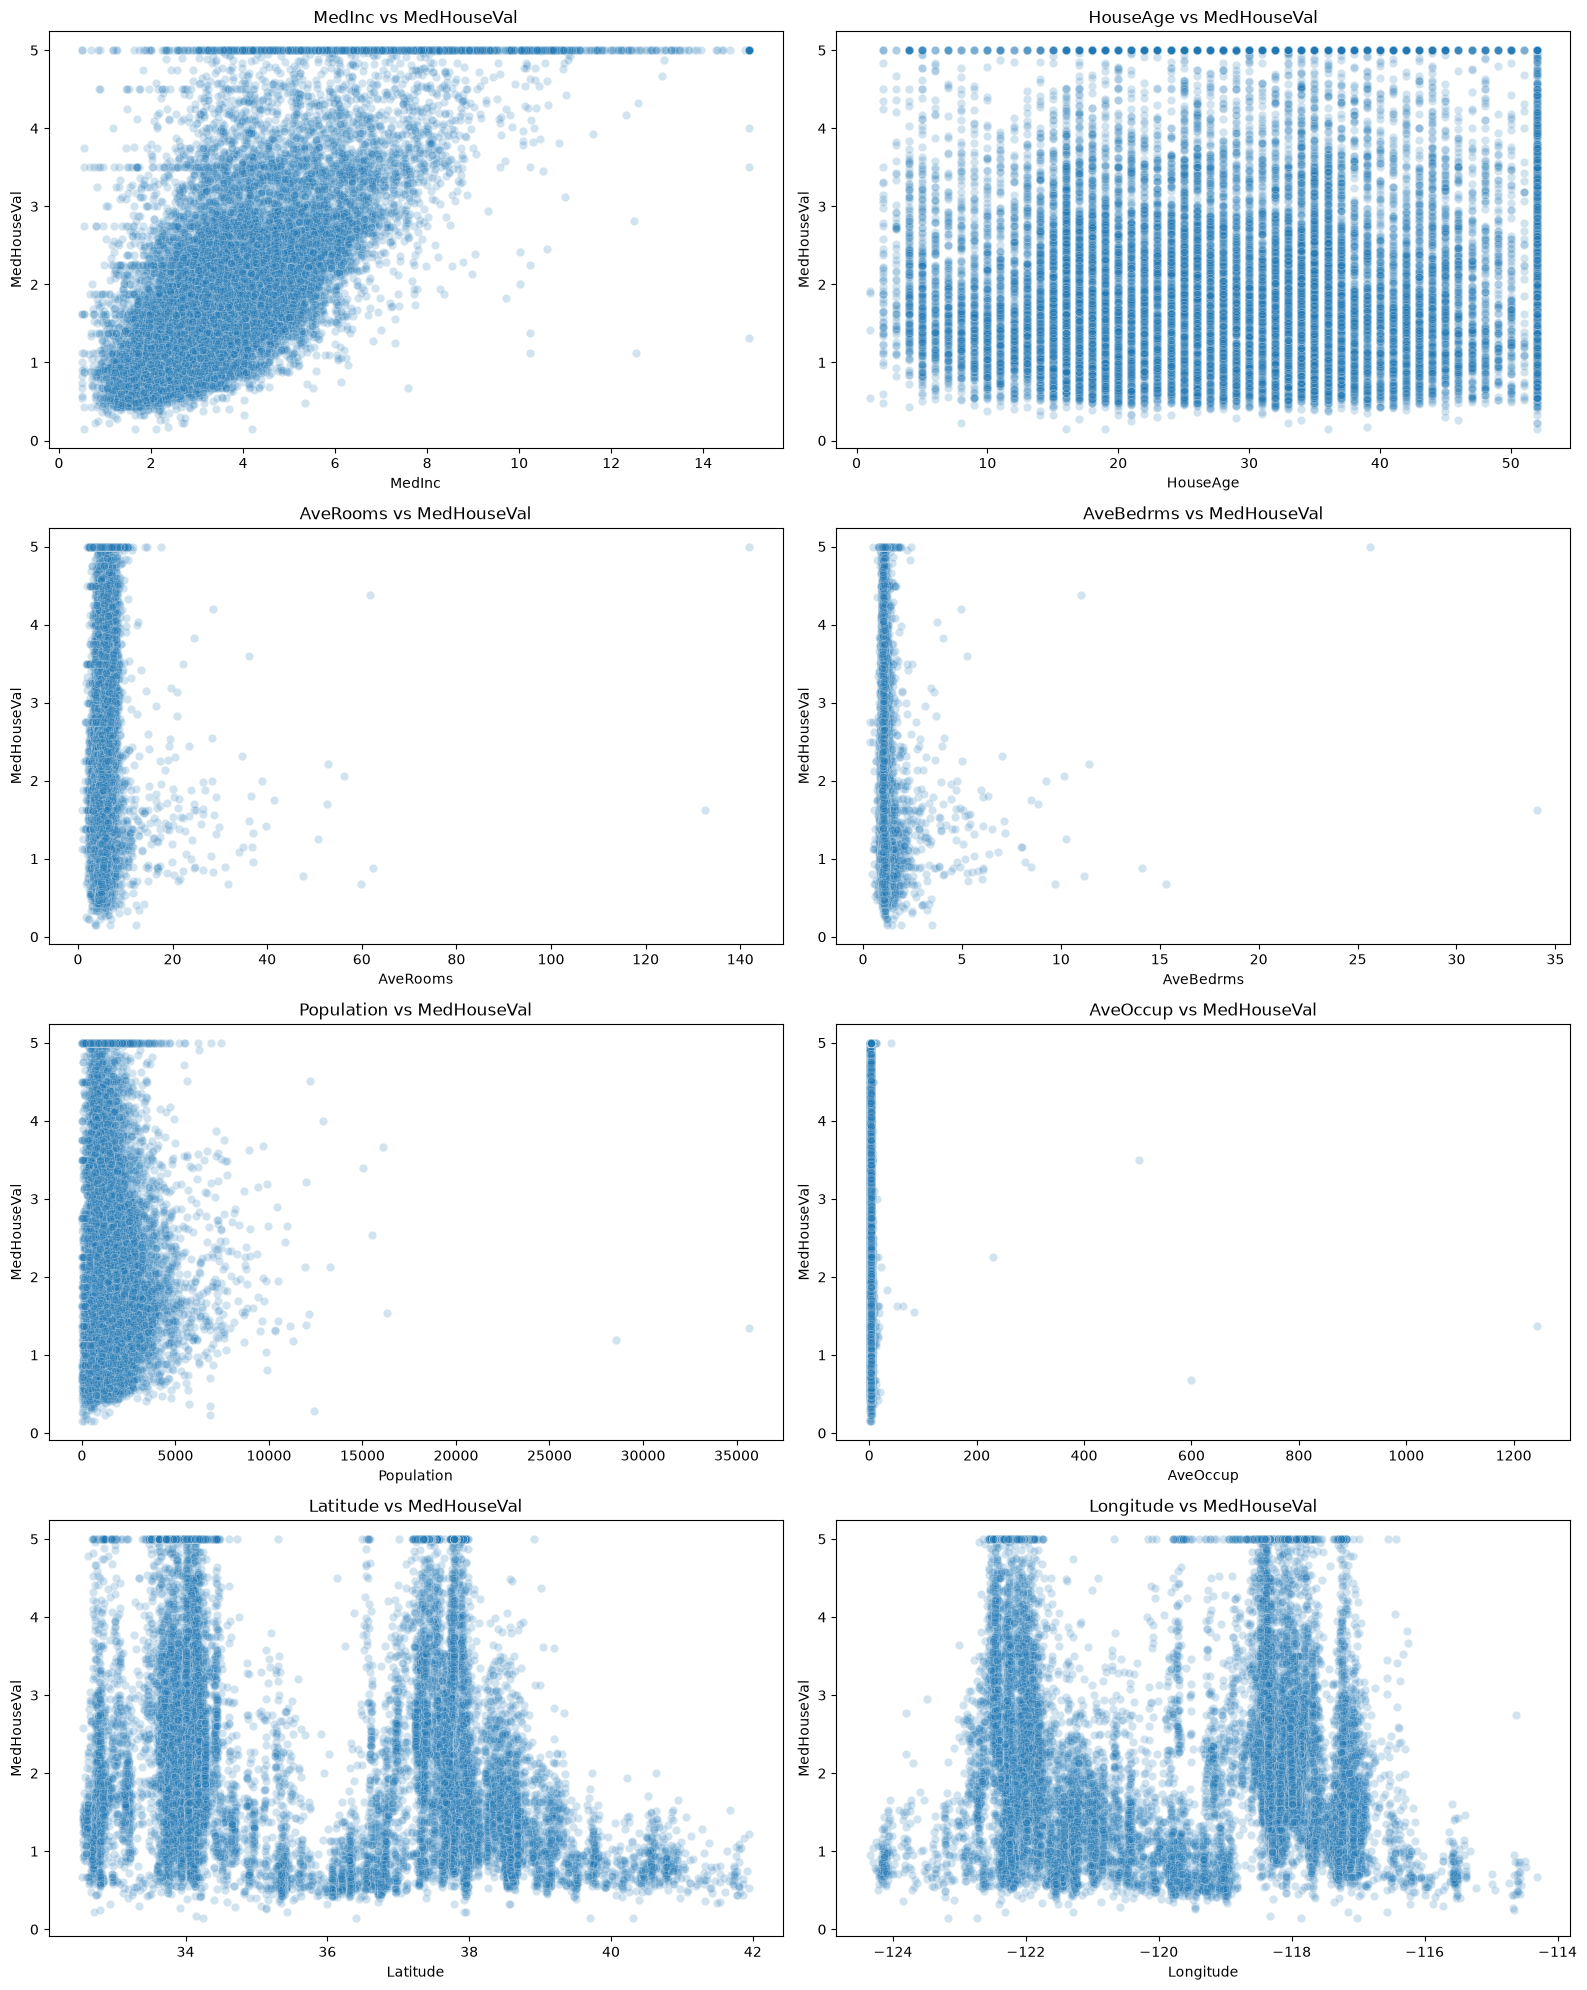

In [33]:
features = df.columns.drop("MedHouseVal")

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()

for ax, feature in zip(axes, features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="MedHouseVal",
        alpha=0.2,
        ax=ax
    )
    ax.set_title(f"{feature} vs MedHouseVal")

plt.tight_layout()
plt.show()

# Investigating the extreme values in AveRooms,AveBedrms and Aveoccup

Your goal is to answer three questions:
1. How extreme are the values?
2. Are they genuine observations or possible data problems?
3. Do they have enough influence on your Linear Regression model to warrant further investigation?

In [70]:
df[["AveRooms", "AveBedrms", "AveOccup","Population"]].describe(percentiles=[0.01, 0.50, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
AveRooms,20640.0,5.429000,2.474173,0.846154,2.581133,5.229129,10.357033,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,0.872840,1.048780,2.127541,34.066667
AveOccup,20640.0,3.070655,10.386050,0.692308,1.536686,2.818116,5.394812,1243.333333
Population,20640.0,1425.476744,1132.462122,3.000000,88.000000,1166.000000,5805.830000,35682.000000


# observation


# 99 percentile of values in :
 ### AvgRooms <= 10.357
 ### AveBedrms <= 2.12
 ### AvgOccup <= 5.39, 
 ### Population <= 5805.83
 but thier maximum values are way too extreme.<br>
 AvgRooms max  is 14x fold greater than the 99 percentile value.<br>
 similarly, AveBedrms is approx. 17x fold greater. <br>
 AveOccup is approx. 250x fold greater.<br>
 and Population is 7x fold greater than the 99 percentile value. <br>
 so these values are way too extreme from the rest of the data.



In [43]:
df[df['AveRooms'] > 10.357033].shape

(207, 9)

In [47]:
df['AveRooms'].nlargest(10)

1914     141.909091
1979     132.533333
12447     62.422222
1913      61.812500
11862     59.875000
1912      56.269231
9676      52.848214
11707     52.690476
2395      50.837838
1240      47.515152
Name: AveRooms, dtype: float64

In [53]:
df[df['AveBedrms'] > 2.127541].shape

(207, 9)

In [54]:
df['AveBedrms'].nlargest(10)

1979     34.066667
1914     25.636364
11862    15.312500
12447    14.111111
9676     11.410714
1240     11.181818
1913     11.000000
2395     10.270270
1912     10.153846
1102      9.703704
Name: AveBedrms, dtype: float64

In [59]:
df[['AveRooms','AveBedrms']].sort_values(by='AveBedrms',ascending=False).head(10)

,AveRooms,AveBedrms
1979,132.533333,34.066667
1914,141.909091,25.636364
11862,59.875000,15.312500
12447,62.422222,14.111111
9676,52.848214,11.410714
1240,47.515152,11.181818
1913,61.812500,11.000000
2395,50.837838,10.270270
1912,56.269231,10.153846
1102,31.777778,9.703704


In [60]:
df['AveOccup'].nlargest(10)

19006    1243.333333
3364      599.714286
16669     502.461538
13034     230.172414
9172       83.171429
12104      63.750000
16420      51.400000
8874       41.214286
13366      33.952941
5986       21.333333
Name: AveOccup, dtype: float64

In [71]:
df.nlargest(20, 'AveOccup')[
    ['AveOccup', 'AveRooms', 'AveBedrms',
     'Population', 'HouseAge', 'MedHouseVal']
]

,AveOccup,AveRooms,AveBedrms,Population,HouseAge,MedHouseVal
19006,1243.333333,3.166667,0.833333,7460.0,45.0,1.37500
3364,599.714286,5.142857,1.142857,4198.0,36.0,0.67500
16669,502.461538,9.076923,1.307692,6532.0,46.0,3.50000
13034,230.172414,8.275862,1.517241,6675.0,52.0,2.25000
9172,83.171429,5.123810,0.933333,8733.0,5.0,1.54600
12104,63.750000,7.600000,0.950000,1275.0,8.0,1.62500
16420,51.400000,5.366667,0.900000,1542.0,26.0,1.62500
8874,41.214286,7.285714,1.214286,1154.0,52.0,5.00001
13366,33.952941,5.258824,1.117647,2886.0,36.0,1.83300
5986,21.333333,4.500000,1.206349,2688.0,52.0,2.12500


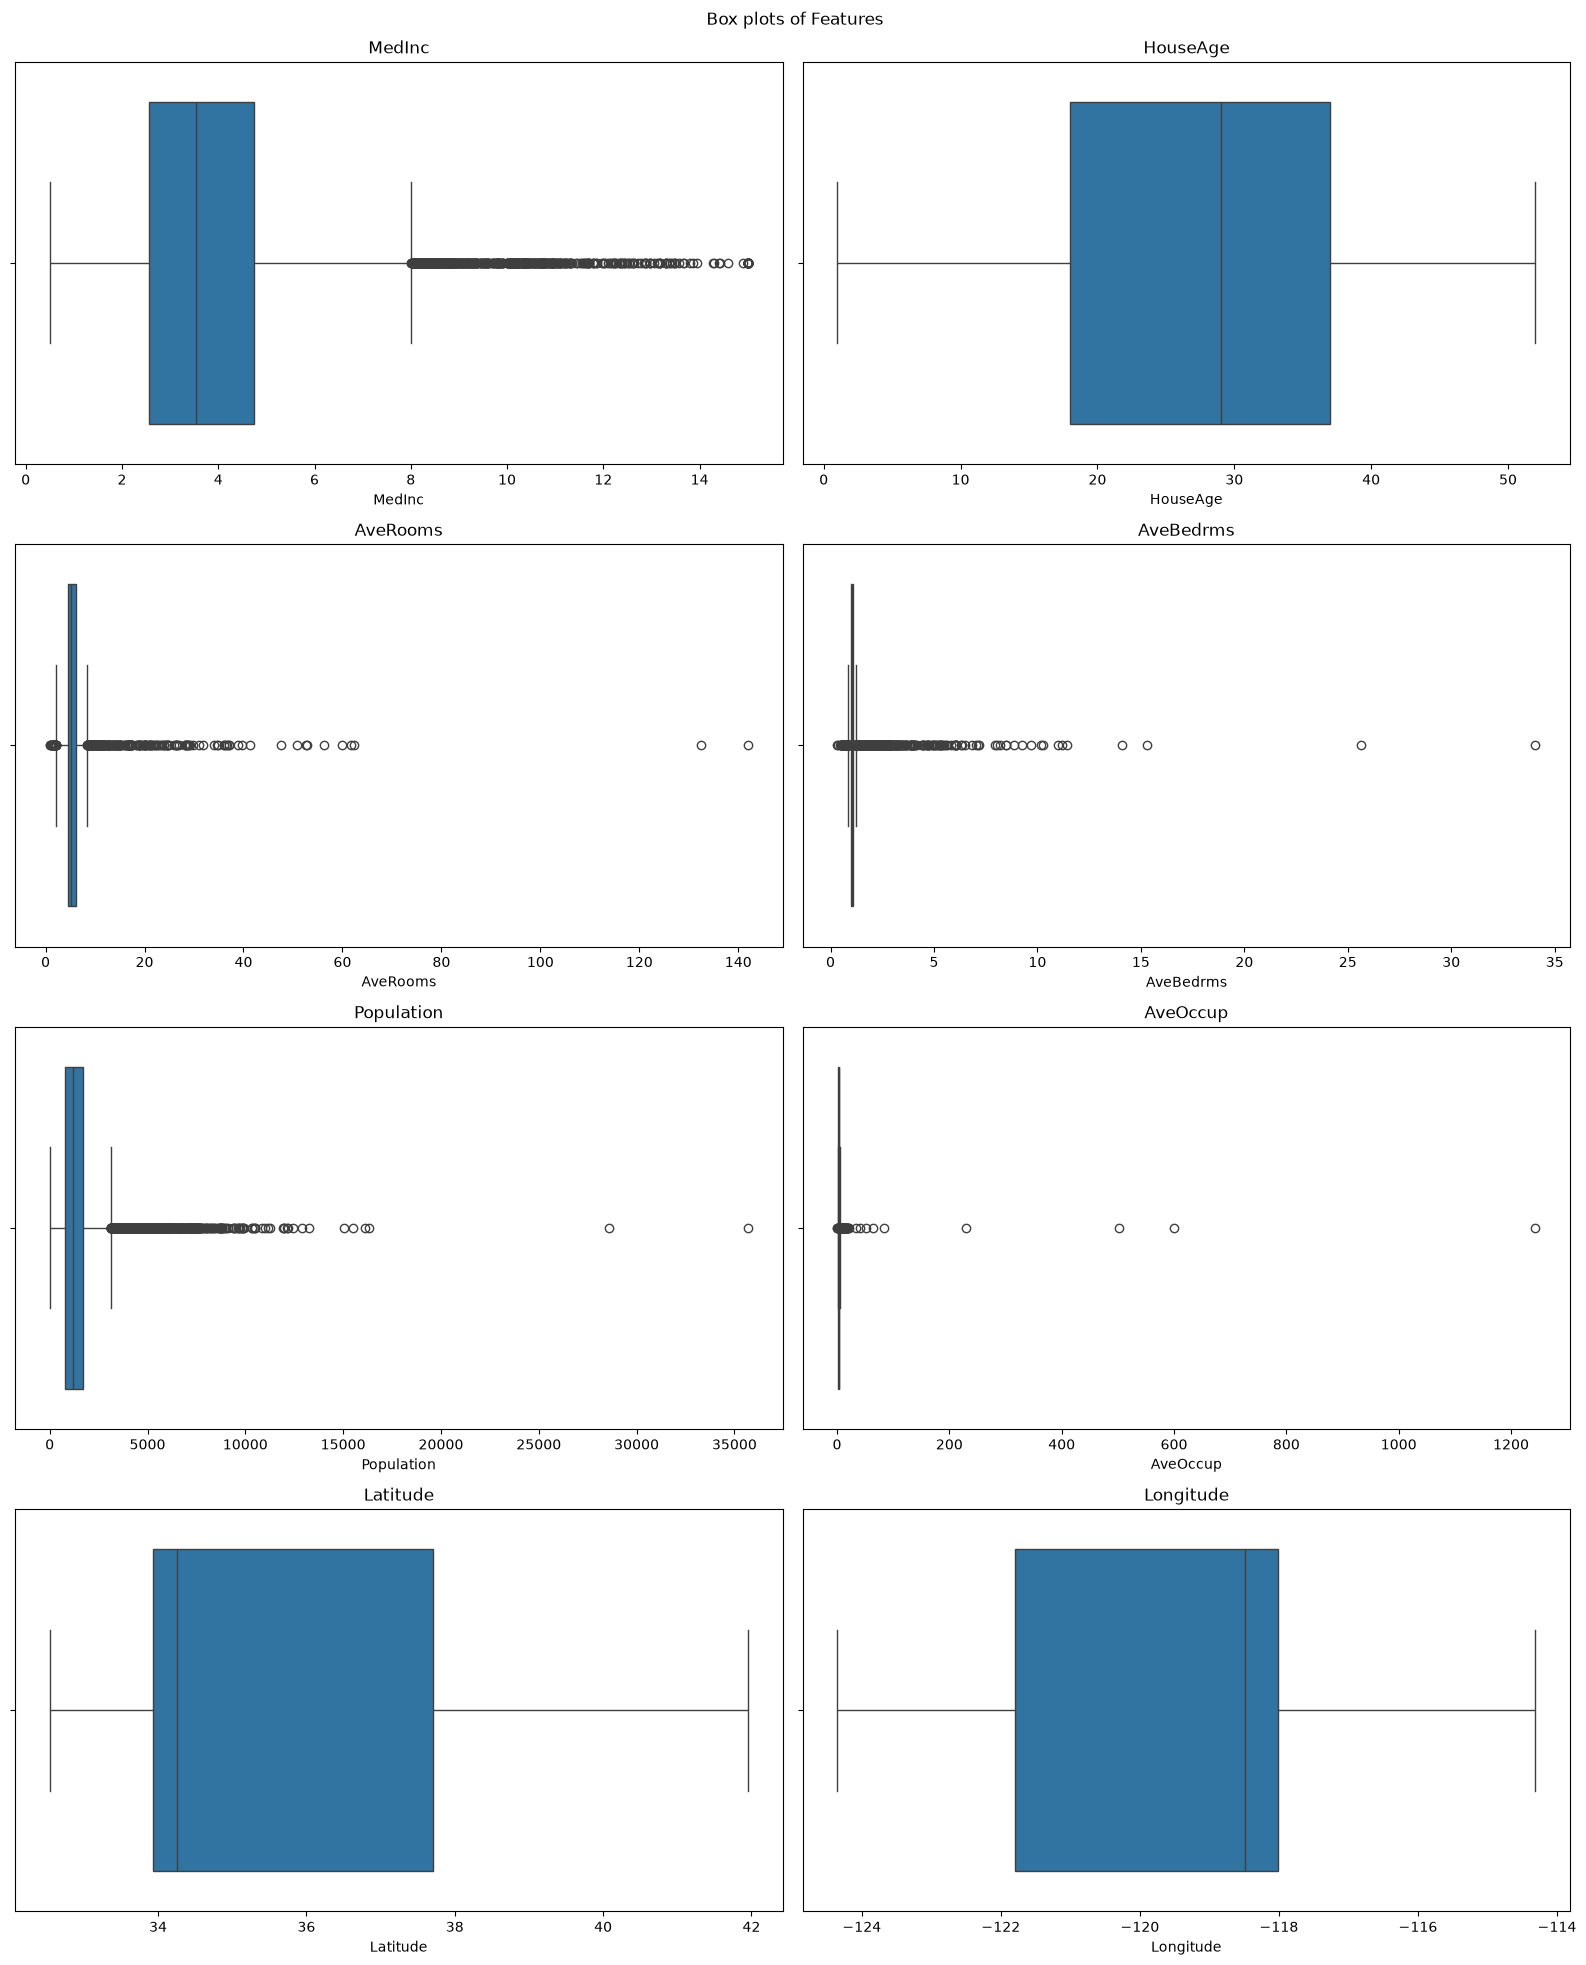

In [69]:
features = df.columns.drop("MedHouseVal")

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()
for ax,feature in zip(axes,features):
    sns.boxplot(data=df,x=feature,ax=ax)
    ax.set_title(f"{feature}")
plt.suptitle("Box plots of Features\n")    
plt.tight_layout()
plt.show()

# Data profile

In [75]:
profile = pd.DataFrame({
    "dtype": X_train.dtypes,
    "missing": X_train.isna().sum(),
    "unique": X_train.nunique(),
    "min": X_train.min(),
    "q01": X_train.quantile(0.01),
    "q25": X_train.quantile(0.25),
    "median": X_train.quantile(0.50),
    "q75": X_train.quantile(0.75),
    "q99": X_train.quantile(0.99),
    "max": X_train.max(),
    "skew": X_train.skew()
})

profile

,dtype,missing,unique,min,q01,q25,median,q75,q99,max,skew
MedInc,float64,0,10900,0.499900,1.077341,2.562500,3.531300,4.733225,10.547041,15.000100,1.634607
HouseAge,float64,0,52,1.000000,4.000000,18.000000,29.000000,37.000000,52.000000,52.000000,0.062843
AveRooms,float64,0,15698,0.846154,2.577291,4.441027,5.224884,6.047464,10.190260,132.533333,17.500514
AveBedrms,float64,0,11966,0.333333,0.870436,1.006231,1.048420,1.099243,2.096506,34.066667,33.307257
Population,float64,0,3658,3.000000,88.000000,788.000000,1168.000000,1738.000000,5857.690000,35682.000000,5.250859
AveOccup,float64,0,15316,0.692308,1.545038,2.430380,2.821348,3.290106,5.404066,1243.333333,98.842632
Latitude,float64,0,840,32.540000,32.680000,33.930000,34.250000,37.710000,40.630000,41.950000,0.473196
Longitude,float64,0,828,-124.350000,-123.220000,-121.790000,-118.490000,-118.010000,-116.250000,-114.310000,-0.298204


# Outlier Summary

In [76]:
outlier_summary = []

for column in X_train.columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (X_train[column] < lower) | (X_train[column] > upper)

    outlier_summary.append({
        "feature": column,
        "lower_bound": lower,
        "upper_bound": upper,
        "flagged_count": mask.sum(),
        "flagged_percent": mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,feature,lower_bound,upper_bound,flagged_count,flagged_percent
0,MedInc,-0.693588,7.989313,555,3.361192
1,HouseAge,-10.500000,65.500000,0,0.000000
2,AveRooms,2.031371,8.457119,412,2.495155
3,AveBedrms,0.866712,1.238762,1143,6.922238
4,Population,-637.000000,3163.000000,951,5.759448
5,AveOccup,1.140790,4.579696,571,3.458091
6,Latitude,28.260000,43.380000,0,0.000000
7,Longitude,-127.460000,-112.340000,0,0.000000


In [110]:
iqr_flags = pd.DataFrame(index=X_train.index)

for column in feature_columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_flags[column] = (
        (X_train[column] < lower) |
        (X_train[column] > upper)
    )
iqr_flags["n_flagged_features"] = iqr_flags.sum(axis=1)
print("Rows flagged by at least one feature:",
      (iqr_flags["n_flagged_features"] > 0).sum())

print("Percentage of training rows flagged:",
      (iqr_flags["n_flagged_features"] > 0).mean() * 100)

iqr_flags["n_flagged_features"].value_counts().sort_index()
iqr_flags.sample(5)

Rows flagged by at least one feature: 3038
Percentage of training rows flagged: 18.398740310077518


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,n_flagged_features
2525,False,False,False,False,False,False,False,False,0
2292,False,False,False,False,False,False,False,False,0
4546,False,False,False,False,False,False,False,False,0
14258,False,False,False,False,False,False,False,False,0
1610,False,False,False,False,False,False,False,False,0


In [111]:
most_flagged_indices = (
    iqr_flags["n_flagged_features"]
    .sort_values(ascending=False)
    .head(20)
    .index
)

df.loc[
    most_flagged_indices,
    [
        "MedInc", "HouseAge", "AveRooms", "AveBedrms",
        "Population", "AveOccup", "Latitude",
        "Longitude", "MedHouseVal"
    ]
]

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
10405,10.9704,6.0,10.558140,2.372093,213.0,4.953488,33.69,-117.53,4.83300
10519,10.1122,2.0,8.786655,1.275680,3550.0,3.116769,33.57,-117.68,5.00001
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.37500
12077,6.2308,2.0,8.801008,1.373804,5964.0,3.004534,33.87,-117.64,2.57900
14803,8.7991,10.0,9.287154,1.457179,1900.0,2.392947,32.63,-117.13,4.78500
12375,4.0840,7.0,9.658791,1.911538,3581.0,1.967582,33.74,-116.38,1.94500
17891,3.3750,34.0,11.384615,2.153846,132.0,10.153846,37.40,-121.93,0.67500
12374,3.3799,6.0,10.860423,2.036020,4176.0,1.880234,33.78,-116.36,2.39300
15183,7.2731,4.0,8.861439,1.343750,5613.0,3.309552,33.02,-117.15,4.50400
4352,15.0001,37.0,8.659574,1.425532,100.0,2.127660,34.10,-118.37,5.00001
